# Energy Sector Excess Returns: Explanation and Prediction
Edouard Atanesyan

Originally completed for BUFN640 (Financial Data Analytics), University of Maryland, Fall 2026.

Sector: Energy (Enrgy) from the 10 Industry Portfolios on Ken French's website.

# Importing the Python modules

In [1]:
#Importing relevant libraries
import warnings; warnings.simplefilter('ignore')
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt

import pandas_datareader.data as web
import statsmodels.formula.api as sm
from statsmodels.iolib.summary2 import summary_col

# Loading the data

## Industry portfolios from Ken French's website
Monthly returns on the 10 industry portfolios. The data is in percent, so we divide by 100.

In [2]:
r = web.DataReader('10_Industry_Portfolios', 'famafrench', start=1900)[0]/100
r.head()

,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
Date,,,,,,,,,,
1926-07,0.0144,0.1558,0.0470,-0.0114,0.0290,0.0083,0.0012,0.0185,0.0704,0.0214
1926-08,0.0399,0.0370,0.0280,0.0343,0.0266,0.0217,-0.0072,0.0417,-0.0170,0.0435
1926-09,0.0115,0.0498,0.0117,-0.0330,-0.0039,0.0242,0.0021,0.0069,0.0205,0.0031
1926-10,-0.0124,-0.0839,-0.0365,-0.0078,-0.0458,-0.0011,-0.0229,-0.0057,-0.0327,-0.0285
1926-11,0.0521,-0.0017,0.0427,0.0001,0.0471,0.0163,0.0645,0.0543,0.0440,0.0213


## Fama-French factors and the risk-free rate
We load the 5 Fama-French factors and the momentum factor.

In [3]:
df_factors = web.DataReader('F-F_Research_Data_5_Factors_2x3', 'famafrench', start=1900)[0]/100
df_factors.rename(columns={'Mkt-RF': 'MKT'}, inplace=True)

# Momentum factor
mom = web.DataReader('F-F_Momentum_Factor', 'famafrench', start=1900)[0]/100
mom.columns = ['Mom']

df_factors.tail()

,MKT,SMB,HML,RMW,CMA,RF
Date,,,,,,
2026-05,0.0491,-0.0265,-0.0231,-0.0816,-0.0146,0.0031
2026-06,-0.0107,0.0436,0.0358,-0.0507,0.0345,0.0029
2026-07,-0.0061,-0.0009,0.0211,0.1107,0.0227,0.0033
2026-08,0.0256,-0.0052,-0.0354,-0.0409,-0.0201,0.0029
2026-09,-0.0107,-0.0460,-0.0155,-0.0322,0.0108,0.0031


## Macroeconomic data from FRED
We load nine monthly series from FRED.

In [4]:
# start and end date
start_date = datetime(1960, 1, 1)
end_date = datetime(2026, 8, 31)

cpi = web.DataReader('CPIAUCSL', 'fred', start_date, end_date)    # consumer price index
indpro = web.DataReader('INDPRO', 'fred', start_date, end_date)   # industrial production
unrate = web.DataReader('UNRATE', 'fred', start_date, end_date)   # unemployment rate
oil = web.DataReader('WTISPLC', 'fred', start_date, end_date)     # oil price (WTI)
gs10 = web.DataReader('GS10', 'fred', start_date, end_date)       # 10-year Treasury yield
tb3 = web.DataReader('TB3MS', 'fred', start_date, end_date)       # 3-month T-bill rate
ff = web.DataReader('FEDFUNDS', 'fred', start_date, end_date)     # federal funds rate
baa = web.DataReader('BAA', 'fred', start_date, end_date)         # Baa corporate bond yield
aaa = web.DataReader('AAA', 'fred', start_date, end_date)         # Aaa corporate bond yield

fred = pd.concat([cpi, indpro, unrate, oil, gs10, tb3, ff, baa, aaa], axis=1)

# using the monthly dates, same as the Ken French data
fred.index = pd.PeriodIndex(fred.index, freq='M')
fred.index.name = 'Date'

# October 2025 CPI and unemployment were not published due to a government shutdown
# carry the previous value forward for that month
fred = fred.ffill()
fred.tail()

,CPIAUCSL,INDPRO,UNRATE,WTISPLC,GS10,TB3MS,FEDFUNDS,BAA,AAA
Date,,,,,,,,,
2026-04,332.407,102.5768,4.3,100.32,4.32,3.61,3.64,6.03,5.42
2026-05,333.979,102.7232,4.3,102.13,4.48,3.60,3.63,6.10,5.56
2026-06,332.568,102.9610,4.2,84.81,4.47,3.66,3.63,6.00,5.52
2026-07,332.813,103.2006,4.1,80.46,4.60,3.73,3.63,6.19,5.76
2026-08,334.131,103.2664,4.1,83.90,4.68,3.72,3.63,6.32,5.88


We use log growth rates for prices and production, and changes for interest rates and unemployment as stationary variables

In [5]:
macro = pd.DataFrame(index=fred.index)
macro['OIL'] = np.log(1 + fred['WTISPLC'].pct_change())    # oil price growth
macro['INFL'] = np.log(1 + fred['CPIAUCSL'].pct_change())  # inflation
macro['IPG'] = np.log(1 + fred['INDPRO'].pct_change())     # industrial production growth
macro['dUNR'] = fred['UNRATE'].diff()/100                  # change in unemployment rate
macro['dGS10'] = fred['GS10'].diff()/100                   # change in 10-year yield
macro['dFF'] = fred['FEDFUNDS'].diff()/100                 # change in fed funds rate
macro['dTERM'] = (fred['GS10'] - fred['TB3MS']).diff()/100 # change in term spread (10-year minus 3-month)
macro['dDEF'] = (fred['BAA'] - fred['AAA']).diff()/100     # change in default spread (Baa minus Aaa)
macro.tail()

,OIL,INFL,IPG,dUNR,dGS10,dFF,dTERM,dDEF
Date,,,,,,,,
2026-04,0.093338,0.006380,0.008254,0.000,0.0007,0.0000,0.0007,0.0005
2026-05,0.017881,0.004718,0.001426,0.000,0.0016,-0.0001,0.0017,-0.0007
2026-06,-0.185833,-0.004234,0.002312,-0.001,-0.0001,0.0000,-0.0007,-0.0006
2026-07,-0.052653,0.000736,0.002324,-0.001,0.0013,0.0000,0.0006,-0.0005
2026-08,0.041865,0.003952,0.000637,0.000,0.0008,0.0000,0.0009,0.0001


# Why Energy?
For each sector we run a CAPM regression, a regression with the Fama-French factors and momentum, and a regression that also adds the macro variables. We stored the results in lists

In [6]:
sectors = ['NoDur', 'Durbl', 'Manuf', 'Enrgy', 'HiTec', 'Telcm', 'Shops', 'Hlth', 'Utils']

# made some empty lists to store the results
capm_betas = []
capm_r2 = []
ff_r2 = []
macro_r2 = []

for sector in sectors:
  data = pd.concat([r[sector], df_factors, mom, macro], axis=1).dropna()
  data = data.loc['1963-07':]
  data['y'] = data[sector] - data['RF']   # excess return

  capm = sm.ols(formula='y ~ MKT', data=data).fit()
  ffm = sm.ols(formula='y ~ MKT + SMB + HML + RMW + CMA + Mom', data=data).fit()
  full = sm.ols(formula='y ~ MKT + SMB + HML + RMW + CMA + Mom + OIL + INFL + IPG + dUNR + dGS10 + dFF + dTERM + dDEF', data=data).fit()

  # storing results
  capm_betas += [capm.params['MKT']]
  capm_r2 += [capm.rsquared]
  ff_r2 += [ffm.rsquared]
  macro_r2 += [full.rsquared]

screen = pd.DataFrame({'CAPM beta': capm_betas, 'CAPM R2': capm_r2,
                       'Factors R2': ff_r2, 'Factors + macro R2': macro_r2}, index=sectors)
screen['R2 added by macro'] = screen['Factors + macro R2'] - screen['Factors R2']
print(round(screen, 3))

       CAPM beta  CAPM R2  Factors R2  Factors + macro R2  R2 added by macro
NoDur      0.761    0.650       0.749               0.756              0.007
Durbl      1.251    0.558       0.596               0.604              0.008
Manuf      1.035    0.849       0.877               0.880              0.003
Enrgy      0.840    0.378       0.458               0.527              0.069
HiTec      1.235    0.750       0.836               0.841              0.005
Telcm      0.770    0.534       0.577               0.581              0.005
Shops      1.000    0.751       0.788               0.797              0.008
Hlth       0.809    0.568       0.619               0.628              0.009
Utils      0.522    0.330       0.427               0.462              0.035


Energy has one of the lowest R2 values in both the CAPM (0.38) and the factor model (0.46), so standard factors leave most of its returns unexplained. It is also the sector where the macro variables add the most (R2 rises by 0.07). Energy returns should depend on oil prices, which gives us a clear economic story to test.

# Building the datasets

## Monthly data
The sample starts in July 1963, when the Fama-French 5 factors start, and ends in August 2026. The dependent variable y is the Energy return minus the risk-free rate.

In [7]:
m = pd.concat([r['Enrgy'], df_factors, mom, macro], axis=1).dropna()
m = m.loc['1963-07':]
m['y'] = m['Enrgy'] - m['RF']   # Energy excess return
print('Number of months:', len(m))
m.head()

Number of months: 758


,Enrgy,MKT,SMB,HML,RMW,CMA,RF,Mom,OIL,INFL,IPG,dUNR,dGS10,dFF,dTERM,dDEF,y
Date,,,,,,,,,,,,,,,,,
1963-07,0.0230,-0.0039,-0.0048,-0.0084,0.0064,-0.0115,0.0027,0.0101,0.0,0.002610,-0.003988,0.000,0.0003,0.0003,-0.0016,-0.0003,0.0203
1963-08,0.0394,0.0508,-0.0080,0.0172,0.0040,-0.0038,0.0025,0.0100,0.0,0.001953,0.001994,-0.002,-0.0002,0.0047,-0.0016,-0.0004,0.0369
1963-09,-0.0365,-0.0157,-0.0043,-0.0002,-0.0078,0.0015,0.0027,0.0012,0.0,-0.000976,0.009922,0.001,0.0008,-0.0001,0.0002,-0.0001,-0.0392
1963-10,-0.0033,0.0254,-0.0134,-0.0003,0.0279,-0.0225,0.0029,0.0313,0.0,0.000976,0.006887,0.000,0.0003,0.0002,-0.0004,-0.0002,-0.0062
1963-11,-0.0114,-0.0086,-0.0085,0.0178,-0.0043,0.0227,0.0027,-0.0077,0.0,0.000975,0.004889,0.002,0.0001,-0.0002,-0.0006,0.0000,-0.0141


## Annual data
We can only add up log returns, so we first take logs, add them up within each year, and convert back. We keep only years with all 12 months. The macro variables are already log growth rates or changes, so we simply add them up within each year.

In [8]:
a = pd.DataFrame()

# annual Energy excess return = annual Energy return minus annual risk-free
enrgy_a = np.exp(np.log(1+m['Enrgy']).resample("Y").agg(pd.Series.sum, min_count=12)) - 1
rf_a = np.exp(np.log(1+m['RF']).resample("Y").agg(pd.Series.sum, min_count=12)) - 1
a['y'] = enrgy_a - rf_a

# annual factor returns
for col in ['MKT', 'SMB', 'HML', 'RMW', 'CMA', 'Mom']:
  a[col] = np.exp(np.log(1+m[col]).resample("Y").agg(pd.Series.sum, min_count=12)) - 1

# annual macro changes
for col in ['OIL', 'INFL', 'IPG', 'dUNR', 'dGS10', 'dFF', 'dTERM', 'dDEF']:
  a[col] = m[col].resample("Y").agg(pd.Series.sum, min_count=12)

a = a.dropna()
print('Number of years:', len(a))
a.tail()

Number of years: 62


,y,MKT,SMB,HML,RMW,CMA,Mom,OIL,INFL,IPG,dUNR,dGS10,dFF,dTERM,dDEF
Date,,,,,,,,,,,,,,,
2021,0.616666,0.238621,-0.015313,0.222001,0.244545,0.100443,-0.029152,0.422057,0.069287,0.022215,-0.028,0.0054,-0.0001,0.0057,-0.0025
2022,0.632314,-0.209896,-0.013526,0.317400,0.084472,0.290898,0.201953,0.063876,0.062079,-0.008048,-0.004,0.0215,0.0402,-0.0204,0.0051
2023,-0.061556,0.208127,-0.039081,-0.110736,0.038014,-0.161337,-0.204612,-0.061230,0.032621,0.008352,0.003,0.0040,0.0123,-0.0059,-0.0026
2024,-0.035868,0.188863,-0.105436,-0.069790,0.041351,-0.083620,0.184682,-0.025068,0.028303,-0.002745,0.003,0.0037,-0.0085,0.0134,-0.0030
2025,0.035722,0.128081,-0.077976,0.065757,-0.101501,-0.048563,-0.021912,-0.190282,0.026187,0.011563,0.003,-0.0025,-0.0076,0.0043,-0.0001


## The 14 initial variables
Financial variables: MKT (market), SMB (size), HML (value), RMW (profitability), CMA (investment), Mom (momentum), dTERM (change in term spread), dDEF (change in default spread), dGS10 (change in 10-year yield).

Macroeconomic variables: OIL (oil price growth), INFL (inflation), IPG (industrial production growth), dUNR (change in unemployment), dFF (change in fed funds rate).

## Are the initial variables correlated with each other?

In [9]:
# correlation matrix
xlist = ['MKT', 'SMB', 'HML', 'RMW', 'CMA', 'Mom', 'OIL', 'INFL', 'IPG', 'dUNR', 'dGS10', 'dFF', 'dTERM', 'dDEF']
print(xlist)

np.set_printoptions(precision=2, suppress=True, linewidth=120)
np.corrcoef([m[x] for x in xlist])

['MKT', 'SMB', 'HML', 'RMW', 'CMA', 'Mom', 'OIL', 'INFL', 'IPG', 'dUNR', 'dGS10', 'dFF', 'dTERM', 'dDEF']


array([[ 1.  ,  0.27, -0.21, -0.19, -0.36, -0.16,  0.05, -0.1 , -0.03,  0.06, -0.15, -0.12,  0.02, -0.06],
       [ 0.27,  1.  ,  0.02, -0.33, -0.08, -0.08,  0.06, -0.01, -0.02,  0.02,  0.03, -0.04,  0.04, -0.09],
       [-0.21,  0.02,  1.  ,  0.1 ,  0.68, -0.19,  0.1 ,  0.1 ,  0.03, -0.03,  0.02, -0.03,  0.08, -0.02],
       [-0.19, -0.33,  0.1 ,  1.  ,  0.02,  0.06, -0.09, -0.07, -0.01,  0.01, -0.01,  0.04, -0.08,  0.04],
       [-0.36, -0.08,  0.68,  0.02,  1.  , -0.02,  0.05,  0.07,  0.01, -0.01,  0.02, -0.04,  0.07,  0.02],
       [-0.16, -0.08, -0.19,  0.06, -0.02,  1.  , -0.05,  0.08,  0.04, -0.06,  0.01,  0.04, -0.06,  0.  ],
       [ 0.05,  0.06,  0.1 , -0.09,  0.05, -0.05,  1.  ,  0.4 ,  0.24, -0.29,  0.21,  0.07,  0.07, -0.25],
       [-0.1 , -0.01,  0.1 , -0.07,  0.07,  0.08,  0.4 ,  1.  ,  0.09, -0.1 ,  0.22,  0.08,  0.05, -0.09],
       [-0.03, -0.02,  0.03, -0.01,  0.01,  0.04,  0.24,  0.09,  1.  , -0.67,  0.14,  0.23, -0.12, -0.2 ],
       [ 0.06,  0.02, -0.03,  0.01, -

Most correlations are small. The largest are HML and CMA (0.68), IPG and dUNR (-0.67), dFF and dTERM (-0.65), and OIL and INFL (0.40). Variables that are highly correlated carry similar information, so both won't stay in the final model.

# How we test the regression assumptions

Residuals: the actual value of y minus the fitted value from the estimated coefficients.

Breusch-Godfrey test: regress the residuals on the regressors and on lags of the residuals. Then use an F-test of the null hypothesis that all the coefficients on the lagged residuals are zero (no autocorrelation).

White's test: regress the squared residuals on the regressors, their squares and their cross products. The F-statistic of this regression tests the null hypothesis that all the slopes are zero (homoscedastic shocks). We read it from the regression output (F-statistic and Prob (F-statistic)).

In both tests we reject the null hypothesis at the 5% level if the p-value is below 0.05.

# Part I: Monthly

## Step 1: CAPM, factor model, and all 14 variables

In [10]:
reg_capm = sm.ols(formula='y ~ MKT', data=m).fit()
reg_ff = sm.ols(formula='y ~ MKT + SMB + HML + RMW + CMA + Mom', data=m).fit()
reg_all = sm.ols(formula='y ~ MKT + SMB + HML + RMW + CMA + Mom + OIL + INFL + IPG + dUNR + dGS10 + dFF + dTERM + dDEF', data=m).fit()
print(reg_all.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.527
Model:                            OLS   Adj. R-squared:                  0.518
Method:                 Least Squares   F-statistic:                     59.14
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          1.31e-110
Time:                        20:36:06   Log-Likelihood:                 1330.4
No. Observations:                 758   AIC:                            -2631.
Df Residuals:                     743   BIC:                            -2561.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0016      0.002     -0.690      0.4

At the 5% level, the significant variables are MKT, HML, RMW, CMA, OIL, dUNR and dFF. The other seven (SMB, Mom, INFL, IPG, dGS10, dTERM, dDEF) are not significant. The F-test below cannot reject that these seven coefficients are jointly zero (p-value 0.11), so we drop them.

In [11]:
# F-test
print(reg_all.f_test('SMB = 0, Mom = 0, INFL = 0, IPG = 0, dGS10 = 0, dTERM = 0, dDEF = 0'))

<F test: F=1.6738395449539207, p=0.11214673603872496, df_denom=743, df_num=7>


## Step 2: Keep only the significant variables

In [12]:
reg_m2 = sm.ols(formula='y ~ MKT + HML + RMW + CMA + OIL + dUNR + dFF', data=m).fit()
print(reg_m2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.520
Model:                            OLS   Adj. R-squared:                  0.515
Method:                 Least Squares   F-statistic:                     115.9
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          6.50e-115
Time:                        20:36:06   Log-Likelihood:                 1324.5
No. Observations:                 758   AIC:                            -2633.
Df Residuals:                     750   BIC:                            -2596.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0021      0.002     -1.298      0.1

All seven variables are significant. But the coefficient on dUNR is positive, which says Energy returns go up when unemployment rises. This does not make economic sense. In April 2020 unemployment jumped by 10.4 percentage points while Energy stocks rebounded by 32%, so one month could be driving this result. To check, we run the same regression on data until December 2019.

In [13]:
# same regression on the sample that ends in December 2019
reg_m2_pre = sm.ols(formula='y ~ MKT + HML + RMW + CMA + OIL + dUNR + dFF', data=m.loc[:'2019-12']).fit()

dfoutput = summary_col([reg_m2, reg_m2_pre], stars=True, float_format='%0.4f',
              model_names=['Full sample', 'Until 2019'],
              info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                         'Adjusted R2':lambda x: "{:.4f}".format(x.rsquared_adj)})
print(dfoutput)
print(m.loc['2020-03':'2020-05', ['y', 'dUNR']])


               Full sample Until 2019
-------------------------------------
Intercept      -0.0021     -0.0019   
               (0.0016)    (0.0015)  
MKT            0.9551***   0.9319*** 
               (0.0384)    (0.0381)  
HML            0.3144***   0.0548    
               (0.0720)    (0.0748)  
RMW            0.2785***   0.2649*** 
               (0.0696)    (0.0709)  
CMA            0.3871***   0.4630*** 
               (0.1076)    (0.1116)  
OIL            0.1613***   0.1353*** 
               (0.0189)    (0.0191)  
dUNR           2.3943***   -1.2188   
               (0.3734)    (0.8799)  
dFF            0.7675**    0.3592    
               (0.3149)    (0.2935)  
R-squared      0.5196      0.5127    
R-squared Adj. 0.5151      0.5076    
Adjusted R2    0.5151      0.5076    
N              758         678       
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01
              y   dUNR
Date                  
2020-03 -0.3459  0.009
2020-04  0.3231  0.104
2020-05  0.0

Before 2020, dUNR is not significant and its sign flips. The result came from the COVID months and not from a stable relationship, so we drop dUNR.

In [14]:
reg_m3 = sm.ols(formula='y ~ MKT + HML + RMW + CMA + OIL + dFF', data=m).fit()
print(reg_m3.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.493
Model:                            OLS   Adj. R-squared:                  0.489
Method:                 Least Squares   F-statistic:                     121.8
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          2.44e-107
Time:                        20:36:06   Log-Likelihood:                 1304.2
No. Observations:                 758   AIC:                            -2594.
Df Residuals:                     751   BIC:                            -2562.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0021      0.002     -1.292      0.1

Without dUNR, dFF is no longer significant at the 5% level (p-value 0.076), so we drop it as well.

## Final monthly model

In [15]:
reg_m = sm.ols(formula='y ~ MKT + HML + RMW + CMA + OIL', data=m).fit()
print(reg_m.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.491
Model:                            OLS   Adj. R-squared:                  0.488
Method:                 Least Squares   F-statistic:                     145.2
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          9.27e-108
Time:                        20:36:06   Log-Likelihood:                 1302.6
No. Observations:                 758   AIC:                            -2593.
Df Residuals:                     752   BIC:                            -2565.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0020      0.002     -1.242      0.2

In [16]:
dfoutput = summary_col([reg_capm, reg_ff, reg_all, reg_m], stars=True, float_format='%0.4f',
              model_names=['CAPM', 'Factors', 'All 14', 'Final'],
              info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                         'Adjusted R2':lambda x: "{:.4f}".format(x.rsquared_adj)})
print(dfoutput)


                  CAPM    Factors    All 14    Final  
------------------------------------------------------
Intercept      0.0019    -0.0017   -0.0016   -0.0020  
               (0.0018)  (0.0017)  (0.0024)  (0.0016) 
MKT            0.8396*** 0.9823*** 0.9858*** 0.9635***
               (0.0392)  (0.0416)  (0.0403)  (0.0389) 
SMB                      -0.0109   -0.0279            
                         (0.0593)  (0.0560)           
HML                      0.3734*** 0.3390*** 0.3051***
                         (0.0789)  (0.0748)  (0.0740) 
RMW                      0.2306*** 0.2725*** 0.2837***
                         (0.0773)  (0.0734)  (0.0715) 
CMA                      0.3717*** 0.3750*** 0.3980***
                         (0.1148)  (0.1083)  (0.1103) 
Mom                      0.0240    0.0480             
                         (0.0408)  (0.0386)           
OIL                                0.1591*** 0.1297***
                                   (0.0210)  (0.0186) 
INFL     

The coefficients in the final model make economic sense. The coefficient on MKT is close to 1, so Energy moves about one-for-one with the market. HML is positive, so Energy behaves like a value sector. RMW and CMA are positive, so Energy behaves like profitable firms that invest conservatively. OIL is positive: when the oil price rises by 10%, Energy excess returns are about 1.3% higher in the same month.

## Are the linear regression assumptions satisfied?
The Durbin-Watson and Jarque-Bera statistics are in the regression output above. Below are the Breusch-Godfrey test (12 lags), White's test, and a histogram of the residuals.

In [17]:
# residuals
m['u'] = reg_m.resid

# Breusch-Godfrey test
formula = 'u ~ MKT + HML + RMW + CMA + OIL'
hypothesis = 'u_lag1 = 0'
for j in range(1, 13):
  m['u_lag' + str(j)] = m['u'].shift(j)
  formula = formula + ' + u_lag' + str(j)
  if j > 1:
    hypothesis = hypothesis + ', u_lag' + str(j) + ' = 0'

aux_bg = sm.ols(formula=formula, data=m).fit()
print(aux_bg.f_test(hypothesis))

<F test: F=2.4575557779334942, p=0.0037989051685385225, df_denom=728, df_num=12>


In [18]:
# White's test
m['u2'] = m['u']**2
xnames = ['MKT', 'HML', 'RMW', 'CMA', 'OIL']
formula = 'u2 ~ MKT + HML + RMW + CMA + OIL'
for i in range(len(xnames)):
  for j in range(i, len(xnames)):
    name = xnames[i] + '_' + xnames[j]
    m[name] = m[xnames[i]] * m[xnames[j]]
    formula = formula + ' + ' + name

aux_white = sm.ols(formula=formula, data=m).fit()
print(aux_white.summary())

                            OLS Regression Results                            
Dep. Variable:                     u2   R-squared:                       0.459
Model:                            OLS   Adj. R-squared:                  0.444
Method:                 Least Squares   F-statistic:                     31.21
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           2.27e-84
Time:                        20:36:07   Log-Likelihood:                 3255.8
No. Observations:                 758   AIC:                            -6470.
Df Residuals:                     737   BIC:                            -6372.
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0005      0.000      3.134      0.0

<Axes: >

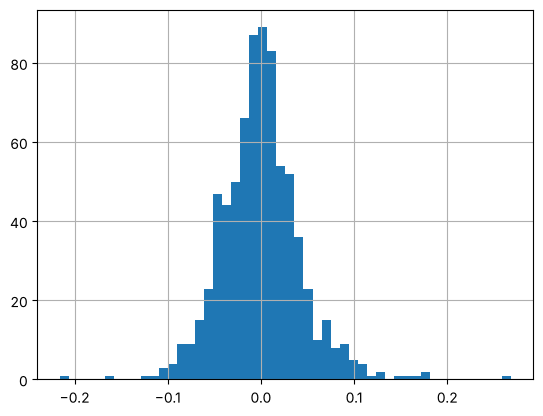

In [19]:
m['u'].hist(bins=50)

Because the shocks are heteroscedastic, we re-estimate the final model with robust standard errors.

In [20]:
# HAC standard errors with the same 12 lags used in the Breusch-Godfrey test
reg_m_robust = sm.ols(formula='y ~ MKT + HML + RMW + CMA + OIL', data=m).fit(cov_type='HAC',cov_kwds={'maxlags':12})

dfoutput = summary_col([reg_m, reg_m_robust], stars=True, float_format='%0.4f',
              model_names=['OLS s.e.', 'Robust s.e.'])
print(dfoutput)
print(reg_m_robust.tvalues)


                OLS s.e. Robust s.e.
------------------------------------
Intercept      -0.0020   -0.0020    
               (0.0016)  (0.0016)   
MKT            0.9635*** 0.9635***  
               (0.0389)  (0.0623)   
HML            0.3051*** 0.3051*    
               (0.0740)  (0.1626)   
RMW            0.2837*** 0.2837**   
               (0.0715)  (0.1147)   
CMA            0.3980*** 0.3980***  
               (0.1103)  (0.1405)   
OIL            0.1297*** 0.1297***  
               (0.0186)  (0.0492)   
R-squared      0.4911    0.4911     
R-squared Adj. 0.4877    0.4877     
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01
Intercept    -1.313073
MKT          15.468670
HML           1.876223
RMW           2.474002
CMA           2.832570
OIL           2.635252
dtype: float64


The assumptions are only partly satisfied. The Durbin-Watson statistic is 2.0, so there is no first-order autocorrelation, but the Breusch-Godfrey test rejects (p-value 0.004), so there is some autocorrelation at longer lags. White's test rejects (F = 31.2, p-value close to 0), so the shocks are heteroscedastic. The Jarque-Bera test rejects normality, which is common for monthly stock returns.

We re-estimate with HAC (Newey-West) standard errors using 12 lags, the same lag length as the Breusch-Godfrey test. MKT, RMW, CMA and OIL stay significant at the 5% level (t-statistics between 2.5 and 15.5). HML is significant only at the 10% level (t = 1.88), so the value tilt is the least robust result in the model; the oil result holds.

# Part I: Annual

## Step 1: CAPM, factor model, and all 14 variables

In [21]:
reg_capm_a = sm.ols(formula='y ~ MKT', data=a).fit()
reg_ff_a = sm.ols(formula='y ~ MKT + SMB + HML + RMW + CMA + Mom', data=a).fit()
reg_all_a = sm.ols(formula='y ~ MKT + SMB + HML + RMW + CMA + Mom + OIL + INFL + IPG + dUNR + dGS10 + dFF + dTERM + dDEF', data=a).fit()
print(reg_all_a.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.738
Model:                            OLS   Adj. R-squared:                  0.660
Method:                 Least Squares   F-statistic:                     9.452
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           2.02e-09
Time:                        20:36:07   Log-Likelihood:                 48.093
No. Observations:                  62   AIC:                            -66.19
Df Residuals:                      47   BIC:                            -34.28
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0669      0.042     -1.589      0.1

At the 5% level, the significant variables are MKT, HML, RMW, OIL, dFF and dDEF. The F-test below cannot reject that the other eight coefficients are jointly zero (p-value 0.69), so we drop them.

In [22]:
# F-test
print(reg_all_a.f_test('SMB = 0, CMA = 0, Mom = 0, INFL = 0, IPG = 0, dUNR = 0, dGS10 = 0, dTERM = 0'))

<F test: F=0.6982143567503941, p=0.6912619179925643, df_denom=47, df_num=8>


## Final annual model

In [23]:
reg_a = sm.ols(formula='y ~ MKT + HML + RMW + OIL + dFF + dDEF', data=a).fit()
print(reg_a.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.707
Model:                            OLS   Adj. R-squared:                  0.675
Method:                 Least Squares   F-statistic:                     22.09
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           4.83e-13
Time:                        20:36:07   Log-Likelihood:                 44.612
No. Observations:                  62   AIC:                            -75.22
Df Residuals:                      55   BIC:                            -60.33
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0578      0.022     -2.608      0.0

In [24]:
dfoutput = summary_col([reg_capm_a, reg_ff_a, reg_all_a, reg_a], stars=True, float_format='%0.4f',
              model_names=['CAPM', 'Factors', 'All 14', 'Final'],
              info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                         'Adjusted R2':lambda x: "{:.4f}".format(x.rsquared_adj)})
print(dfoutput)


                  CAPM    Factors    All 14    Final   
-------------------------------------------------------
Intercept      0.0384    -0.0657*  -0.0669   -0.0578** 
               (0.0277)  (0.0363)  (0.0421)  (0.0222)  
MKT            0.5633*** 0.9618*** 1.1784*** 1.0480*** 
               (0.1513)  (0.1727)  (0.1587)  (0.1292)  
SMB                      0.0736    0.0222              
                         (0.1961)  (0.1520)            
HML                      0.5875**  0.7543*** 0.8120*** 
                         (0.2614)  (0.2253)  (0.1277)  
RMW                      0.3765    0.5682*** 0.5093**  
                         (0.2706)  (0.2038)  (0.1920)  
CMA                      0.2899    0.3186              
                         (0.3647)  (0.2971)            
Mom                      0.3816**  0.1230              
                         (0.1622)  (0.1639)            
OIL                                0.2254*** 0.2431*** 
                                   (0.0722)  (0

In [25]:
# correlation matrix of y, MKT and dDEF
np.corrcoef([a['y'], a['MKT'], a['dDEF']])

array([[ 1.  ,  0.43, -0.27],
       [ 0.43,  1.  , -0.56],
       [-0.27, -0.56,  1.  ]])

The final annual model has an adjusted R2 of 0.67, compared with 0.17 for the CAPM and 0.36 for the factor model.

The positive coefficient on dFF makes sense: the Fed raises rates in years with high inflation and strong demand, and those are good years for Energy (for example 2022).

The positive coefficient on dDEF is harder to interpret. On its own, dDEF is negatively correlated with Energy returns (-0.27), as we would expect. The sign turns positive only because MKT is also in the model and dDEF is strongly negatively correlated with MKT (-0.56). We keep dDEF because it is significant, but we do not base our economic story on it.

## Are the linear regression assumptions satisfied?

In [26]:
# residuals
a['u'] = reg_a.resid

# Breusch-Godfrey test
formula = 'u ~ MKT + HML + RMW + OIL + dFF + dDEF'
hypothesis = 'u_lag1 = 0'
for j in range(1, 3):
  a['u_lag' + str(j)] = a['u'].shift(j)
  formula = formula + ' + u_lag' + str(j)
  if j > 1:
    hypothesis = hypothesis + ', u_lag' + str(j) + ' = 0'

aux_bg = sm.ols(formula=formula, data=a).fit()
print(aux_bg.f_test(hypothesis))

<F test: F=1.102921531970396, p=0.3396851786948217, df_denom=51, df_num=2>


In [27]:
# White's test
a['u2'] = a['u']**2
xnames = ['MKT', 'HML', 'RMW', 'OIL', 'dFF', 'dDEF']
formula = 'u2 ~ MKT + HML + RMW + OIL + dFF + dDEF'
for i in range(len(xnames)):
  for j in range(i, len(xnames)):
    name = xnames[i] + '_' + xnames[j]
    a[name] = a[xnames[i]] * a[xnames[j]]
    formula = formula + ' + ' + name

aux_white = sm.ols(formula=formula, data=a).fit()
print(aux_white.summary())

                            OLS Regression Results                            
Dep. Variable:                     u2   R-squared:                       0.636
Model:                            OLS   Adj. R-squared:                  0.346
Method:                 Least Squares   F-statistic:                     2.196
Date:                Mon, 02 Nov 2026   Prob (F-statistic):             0.0154
Time:                        20:36:07   Log-Likelihood:                 177.38
No. Observations:                  62   AIC:                            -298.8
Df Residuals:                      34   BIC:                            -239.2
Df Model:                          27                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0034      0.008      0.434      0.6

<Axes: >

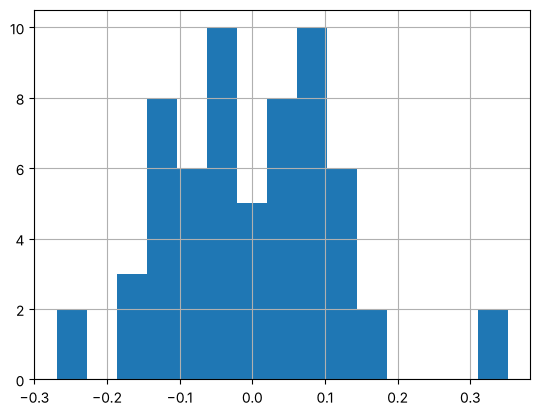

In [28]:
a['u'].hist(bins=15)

In [29]:
# HAC standard errors with the same 2 lags used in the Breusch-Godfrey test
reg_a_robust = sm.ols(formula='y ~ MKT + HML + RMW + OIL + dFF + dDEF', data=a).fit(cov_type='HAC',cov_kwds={'maxlags':2})

dfoutput = summary_col([reg_a, reg_a_robust], stars=True, float_format='%0.4f',
              model_names=['OLS s.e.', 'Robust s.e.'])
print(dfoutput)


                OLS s.e.  Robust s.e.
-------------------------------------
Intercept      -0.0578**  -0.0578*** 
               (0.0222)   (0.0211)   
MKT            1.0480***  1.0480***  
               (0.1292)   (0.1283)   
HML            0.8120***  0.8120***  
               (0.1277)   (0.1920)   
RMW            0.5093**   0.5093***  
               (0.1920)   (0.1737)   
OIL            0.2431***  0.2431***  
               (0.0567)   (0.0668)   
dFF            4.4553***  4.4553***  
               (0.8007)   (1.1560)   
dDEF           12.4166*** 12.4166*** 
               (3.9655)   (3.6063)   
R-squared      0.7068     0.7068     
R-squared Adj. 0.6748     0.6748     
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


Most of the assumptions are satisfied in the annual model. The Durbin-Watson statistic is 2.17 and the Breusch-Godfrey test does not reject (p-value 0.34), so there is no autocorrelation. The Jarque-Bera p-value is 0.19, so we do not reject normality. White's test rejects at the 5% level (F = 2.2, p-value 0.015), so there is some heteroscedasticity. With HAC standard errors (2 lags) all variables remain significant at the 5% level, so our conclusions do not change.

## Do similar variables explain monthly and annual returns?

Mostly yes. MKT, HML, RMW and OIL explain Energy returns at both frequencies, and their coefficients are positive in both models. The differences are that CMA matters only monthly, and dFF and dDEF matter only annually.

The macro variables explain much more at the annual frequency. The adjusted R2 is 0.67 in the annual model and 0.49 in the monthly model, and the coefficient on OIL is larger annually (0.24) than monthly (0.13).

# Part II: Monthly prediction

Now we predict next month's Energy excess return using variables that are known today.

We shift returns by -1 period, so that each row has today's variables and next month's return. CPI, industrial production and unemployment are published with a one-month delay, so we lag them by one extra month.

The 12 initial predictors are: bm (Energy book-to-market ratio), TERM (term spread), DEF (default spread), TB3M (3-month T-bill rate), INFL_l (last month's inflation), IPG_l (last month's industrial production growth), dUNR_l (last month's change in unemployment), OIL (oil price growth this month), OIL12 (oil price growth over the last 12 months), y_lag (Energy excess return this month), MKT and HML (this month).

In [30]:
# Energy book-to-market ratio (annual)
bm = web.DataReader('10_Industry_Portfolios', 'famafrench', start=1900)[6]['Enrgy']
bm.name = 'bm'

bmm = pd.DataFrame(bm.values, index=pd.PeriodIndex(bm.index, freq='M'), columns=['bm'])
bmm.index.name = 'Date'
bmm.tail()

,bm
Date,
2022-12,0.56
2023-12,0.43
2024-12,0.51
2025-12,0.56
2026-12,0.57


In [31]:
p = pd.DataFrame(index=m.index)
p['y_next'] = m['y'].shift(-1)     # next month's excess return
p['y_lag'] = m['y']                # this month's excess return
p['MKT'] = m['MKT']
p['HML'] = m['HML']
p['OIL'] = m['OIL']
p['INFL_l'] = m['INFL'].shift(1)   # lagged one extra month because of a publication delay
p['IPG_l'] = m['IPG'].shift(1)
p['dUNR_l'] = m['dUNR'].shift(1)

# interest rate levels and 12-month oil price growth
levels = pd.DataFrame(index=fred.index)
levels['TERM'] = (fred['GS10'] - fred['TB3MS'])/100
levels['DEF'] = (fred['BAA'] - fred['AAA'])/100
levels['TB3M'] = fred['TB3MS']/100
levels['OIL12'] = np.log(fred['WTISPLC'] / fred['WTISPLC'].shift(12))

p = pd.concat([p, levels], axis=1).loc['1963-07':'2026-08']

# use merge_asof() to propagate annual bm observations forward for every month
p = pd.merge_asof(p, bmm, left_on='Date', right_on='Date').set_index('Date')

pm = p.dropna().copy()
print('Number of months:', len(pm))
pm.tail()

Number of months: 756


,y_next,y_lag,MKT,HML,OIL,INFL_l,IPG_l,dUNR_l,TERM,DEF,TB3M,OIL12,bm
Date,,,,,,,,,,,,,
2026-03,-0.0444,0.1256,-0.0518,0.0329,0.348206,0.002666,0.008539,0.001,0.0064,0.0056,0.0361,0.291996,0.56
2026-04,-0.0638,-0.0444,0.0995,-0.0137,0.093338,0.008614,-0.001686,-0.001,0.0071,0.0061,0.0361,0.456695,0.56
2026-05,-0.0596,-0.0638,0.0491,-0.0231,0.017881,0.006380,0.008254,0.000,0.0088,0.0054,0.0360,0.496374,0.56
2026-06,0.1418,-0.0596,-0.0107,0.0358,-0.185833,0.004718,0.001426,0.000,0.0081,0.0048,0.0366,0.218409,0.56
2026-07,0.0683,0.1418,-0.0061,0.0211,-0.052653,-0.004234,0.002312,-0.001,0.0087,0.0043,0.0373,0.162534,0.56


## Step 1: All 12 predictors

In [32]:
pred_all = sm.ols(formula='y_next ~ bm + TERM + DEF + TB3M + INFL_l + IPG_l + dUNR_l + OIL + OIL12 + y_lag + MKT + HML', data=pm).fit()
print(pred_all.summary())

                            OLS Regression Results                            
Dep. Variable:                 y_next   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.9780
Date:                Mon, 02 Nov 2026   Prob (F-statistic):              0.468
Time:                        20:36:07   Log-Likelihood:                 1048.9
No. Observations:                 756   AIC:                            -2072.
Df Residuals:                     743   BIC:                            -2012.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0028      0.008      0.367      0.7

Only bm and TB3M are significant at the 5% level. The F-test below cannot reject that the other ten coefficients are jointly zero (p-value 0.84), so we drop them.

In [33]:
# F-test
print(pred_all.f_test('TERM = 0, DEF = 0, INFL_l = 0, IPG_l = 0, dUNR_l = 0, OIL = 0, OIL12 = 0, y_lag = 0, MKT = 0, HML = 0'))

<F test: F=0.5630665873348468, p=0.8445812138969843, df_denom=743, df_num=10>


## Final monthly predictive model

In [34]:
pred_m = sm.ols(formula='y_next ~ bm + TB3M', data=pm).fit()
print(pred_m.summary())

                            OLS Regression Results                            
Dep. Variable:                 y_next   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                     3.071
Date:                Mon, 02 Nov 2026   Prob (F-statistic):             0.0470
Time:                        20:36:07   Log-Likelihood:                 1046.1
No. Observations:                 756   AIC:                            -2086.
Df Residuals:                     753   BIC:                            -2072.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0008      0.006      0.123      0.9

In [35]:
# residuals
pm['u'] = pred_m.resid

# Breusch-Godfrey test
formula = 'u ~ bm + TB3M'
hypothesis = 'u_lag1 = 0'
for j in range(1, 13):
  pm['u_lag' + str(j)] = pm['u'].shift(j)
  formula = formula + ' + u_lag' + str(j)
  if j > 1:
    hypothesis = hypothesis + ', u_lag' + str(j) + ' = 0'

aux_bg = sm.ols(formula=formula, data=pm).fit()
print(aux_bg.f_test(hypothesis))

<F test: F=1.0446351043271107, p=0.40532681135977233, df_denom=729, df_num=12>


In [36]:
# White's test
pm['u2'] = pm['u']**2
xnames = ['bm', 'TB3M']
formula = 'u2 ~ bm + TB3M'
for i in range(len(xnames)):
  for j in range(i, len(xnames)):
    name = xnames[i] + '_' + xnames[j]
    pm[name] = pm[xnames[i]] * pm[xnames[j]]
    formula = formula + ' + ' + name

aux_white = sm.ols(formula=formula, data=pm).fit()
print(aux_white.summary())

                            OLS Regression Results                            
Dep. Variable:                     u2   R-squared:                       0.031
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     4.725
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           0.000295
Time:                        20:36:08   Log-Likelihood:                 2528.1
No. Observations:                 756   AIC:                            -5044.
Df Residuals:                     750   BIC:                            -5016.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0038      0.003      1.456      0.1

In [37]:
# HAC standard errors with the same 12 lags used in the Breusch-Godfrey test
pred_m_robust = sm.ols(formula='y_next ~ bm + TB3M', data=pm).fit(cov_type='HAC',cov_kwds={'maxlags':12})

dfoutput = summary_col([pred_m, pred_m_robust], stars=True, float_format='%0.4f',
              model_names=['OLS s.e.', 'Robust s.e.'])
print(dfoutput)
print(pred_m_robust.tvalues)


                OLS s.e. Robust s.e.
------------------------------------
Intercept      0.0008    0.0008     
               (0.0063)  (0.0057)   
bm             0.0218**  0.0218**   
               (0.0106)  (0.0098)   
TB3M           -0.1803** -0.1803*   
               (0.0809)  (0.0924)   
R-squared      0.0081    0.0081     
R-squared Adj. 0.0055    0.0055     
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01
Intercept    0.135783
bm           2.234395
TB3M        -1.952448
dtype: float64


Both coefficients make economic sense. The coefficient on bm is positive. When Energy stocks are cheap relative to their book value, future returns are higher. The coefficient on TB3M is negative: high short-term interest rates are followed by lower returns.

The R2 is only 0.8%, so there is very little predictability.

The Breusch-Godfrey test does not reject (p-value 0.41), so there is no autocorrelation. White's test rejects (F = 4.7, p-value close to 0), so the shocks are heteroscedastic. With HAC standard errors (12 lags), bm is still significant at 5% (t = 2.23) but TB3M is significant only at 10% (t = -1.95).

# Part II: Annual prediction

We predict next year's Energy excess return using variables known at the end of this year. Returns are shifted by -1 period. For the interest rate variables we use the December value of each year.

In [38]:
pa = pd.DataFrame(index=a.index)
pa['y_next'] = a['y'].shift(-1)   # next year's excess return
pa['y_lag'] = a['y']              # this year's excess return
pa['MKT'] = a['MKT']
pa['HML'] = a['HML']
pa['OIL'] = a['OIL']
pa['INFL'] = a['INFL']
pa['IPG'] = a['IPG']
pa['dUNR'] = a['dUNR']

# December values of the interest rate variables
dec = levels[['TERM', 'DEF', 'TB3M']].resample("Y").apply(lambda x: x.iloc[-1])

pa = pd.concat([pa, dec, bm], axis=1).loc['1964':'2025']

pay = pa.dropna().copy()
print('Number of years:', len(pay))
pa.tail()

Number of years: 61


,y_next,y_lag,MKT,HML,OIL,INFL,IPG,dUNR,TERM,DEF,TB3M,bm
Date,,,,,,,,,,,,
2021,0.632314,0.616666,0.238621,0.222001,0.422057,0.069287,0.022215,-0.028,0.0141,0.0065,0.0006,0.77
2022,-0.061556,0.632314,-0.209896,0.317400,0.063876,0.062079,-0.008048,-0.004,-0.0063,0.0116,0.0425,0.56
2023,-0.035868,-0.061556,0.208127,-0.110736,-0.061230,0.032621,0.008352,0.003,-0.0122,0.0090,0.0524,0.43
2024,0.035722,-0.035868,0.188863,-0.069790,-0.025068,0.028303,-0.002745,0.003,0.0012,0.0060,0.0427,0.51
2025,NaN,0.035722,0.128081,0.065757,-0.190282,0.026187,0.011563,0.003,0.0055,0.0059,0.0359,0.56


## Step 1: All 11 predictors

In [39]:
pred_all_a = sm.ols(formula='y_next ~ bm + TERM + DEF + TB3M + INFL + IPG + dUNR + OIL + y_lag + MKT + HML', data=pay).fit()
print(pred_all_a.summary())

                            OLS Regression Results                            
Dep. Variable:                 y_next   R-squared:                       0.144
Model:                            OLS   Adj. R-squared:                 -0.048
Method:                 Least Squares   F-statistic:                    0.7497
Date:                Mon, 02 Nov 2026   Prob (F-statistic):              0.686
Time:                        20:36:08   Log-Likelihood:                 10.969
No. Observations:                  61   AIC:                             2.062
Df Residuals:                      49   BIC:                             27.39
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0039      0.123      0.032      0.9

With only 61 years and 11 predictors, none of the variables is significant at the 5% level. We therefore estimate the same two-variable model as in the monthly analysis.

## Final annual predictive model

In [40]:
pred_a = sm.ols(formula='y_next ~ bm + TB3M', data=pay).fit()
print(pred_a.summary())

                            OLS Regression Results                            
Dep. Variable:                 y_next   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.048
Method:                 Least Squares   F-statistic:                     2.509
Date:                Mon, 02 Nov 2026   Prob (F-statistic):             0.0902
Time:                        20:36:08   Log-Likelihood:                 8.7550
No. Observations:                  61   AIC:                            -11.51
Df Residuals:                      58   BIC:                            -5.177
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0113      0.078     -0.145      0.8

In [41]:
# residuals
pay['u'] = pred_a.resid

# Breusch-Godfrey test
formula = 'u ~ bm + TB3M'
hypothesis = 'u_lag1 = 0'
for j in range(1, 3):
  pay['u_lag' + str(j)] = pay['u'].shift(j)
  formula = formula + ' + u_lag' + str(j)
  if j > 1:
    hypothesis = hypothesis + ', u_lag' + str(j) + ' = 0'

aux_bg = sm.ols(formula=formula, data=pay).fit()
print(aux_bg.f_test(hypothesis))

<F test: F=4.089843684976251, p=0.02218815000395026, df_denom=54, df_num=2>


In [42]:
# White's test
pay['u2'] = pay['u']**2
xnames = ['bm', 'TB3M']
formula = 'u2 ~ bm + TB3M'
for i in range(len(xnames)):
  for j in range(i, len(xnames)):
    name = xnames[i] + '_' + xnames[j]
    pay[name] = pay[xnames[i]] * pay[xnames[j]]
    formula = formula + ' + ' + name

aux_white = sm.ols(formula=formula, data=pay).fit()
print(aux_white.summary())

                            OLS Regression Results                            
Dep. Variable:                     u2   R-squared:                       0.144
Model:                            OLS   Adj. R-squared:                  0.066
Method:                 Least Squares   F-statistic:                     1.854
Date:                Mon, 02 Nov 2026   Prob (F-statistic):              0.118
Time:                        20:36:08   Log-Likelihood:                 89.591
No. Observations:                  61   AIC:                            -167.2
Df Residuals:                      55   BIC:                            -154.5
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0116      0.063      0.184      0.8

In [43]:
# the Breusch-Godfrey test rejects, so re-estimate with HAC standard errors (2 lags)
pred_a_robust = sm.ols(formula='y_next ~ bm + TB3M', data=pay).fit(cov_type='HAC',cov_kwds={'maxlags':2})

dfoutput = summary_col([pred_a, pred_a_robust], stars=True, float_format='%0.4f',
              model_names=['OLS s.e.', 'Robust s.e.'])
print(dfoutput)
print(pred_a_robust.tvalues)


               OLS s.e. Robust s.e.
-----------------------------------
Intercept      -0.0113  -0.0113    
               (0.0778) (0.0713)   
bm             0.2605** 0.2605**   
               (0.1284) (0.1227)   
TB3M           -1.7636* -1.7636    
               (0.9726) (1.1543)   
R-squared      0.0796   0.0796     
R-squared Adj. 0.0479   0.0479     
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01
Intercept   -0.158237
bm           2.123255
TB3M        -1.527782
dtype: float64


The signs are the same as in the monthly model. bm is significant at 5% (t = 2.03) and TB3M at 10% (p-value 0.075). The R2 is 8%, about ten times the monthly R2. This is because the predictors change slowly, so the small monthly predictability adds up over the year.

The Breusch-Godfrey test rejects (p-value 0.02), so there is some autocorrelation in the shocks. White's test does not reject (p-value 0.12) and the Jarque-Bera p-value is 0.85, so homoscedasticity and normality are not rejected. With HAC standard errors (2 lags), bm stays significant at 5% (t = 2.12), but TB3M is no longer significant at 10% (t = -1.53).

# Forecasts

We plug the latest values of bm and TB3M into the two predictive models: forecast = intercept + coefficient on bm * bm + coefficient on TB3M * TB3M.

Our data ends in August 2026. So the monthly model gives a forecast for September 2026. The annual model gives a forecast for 2026 using the values at the end of 2025. To look further ahead, we also use the annual model with the latest values (August 2026) to forecast the next 12 months.

In [44]:
# latest month of data (August 2026) to a forecast for next month
latest = p.iloc[-1]
print('Latest bm:', latest['bm'], ' Latest TB3M:', latest['TB3M'])
print('Average bm:', round(pm['bm'].mean(), 2), ' Average TB3M:', round(pm['TB3M'].mean(), 4))

forecast_m = pred_m.params['Intercept'] + pred_m.params['bm']*latest['bm'] + pred_m.params['TB3M']*latest['TB3M']
print('Forecast of excess return for next month (September 2026): {:.2f}%'.format(forecast_m*100))
print('Average monthly excess return: {:.2f}%'.format(pm['y_next'].mean()*100))

Latest bm: 0.56  Latest TB3M: 0.037200000000000004
Average bm: 0.65  Average TB3M: 0.0446
Forecast of excess return for next month (September 2026): 0.63%
Average monthly excess return: 0.69%


In [45]:
# latest full year of data (2025) -> forecast for 2026
latest_a = pa.iloc[-1]
print('Latest bm:', latest_a['bm'], ' Latest TB3M:', latest_a['TB3M'])

forecast_a = pred_a.params['Intercept'] + pred_a.params['bm']*latest_a['bm'] + pred_a.params['TB3M']*latest_a['TB3M']
print('Forecast of excess return for 2026: {:.2f}%'.format(forecast_a*100))
print('Average annual excess return: {:.2f}%'.format(pay['y_next'].mean()*100))

Latest bm: 0.56  Latest TB3M: 0.0359
Forecast of excess return for 2026: 7.13%
Average annual excess return: 7.80%


In [46]:
# forecast for the next 12 months
forecast_12m = pred_a.params['Intercept'] + pred_a.params['bm']*latest['bm'] + pred_a.params['TB3M']*latest['TB3M']
print('Forecast of excess return for the next 12 months: {:.2f}%'.format(forecast_12m*100))
print('Average annual excess return: {:.2f}%'.format(pay['y_next'].mean()*100))

Forecast of excess return for the next 12 months: 6.90%
Average annual excess return: 7.80%


In [47]:
# January to August
ytd = m.loc['2026', 'y']
print('Energy excess return, January to August 2026: {:.2f}%'.format((np.exp(np.log(1+ytd).sum()) - 1)*100))

Energy excess return, January to August 2026: 42.13%


All three forecasts are positive but slightly below the historical average. The Energy book-to-market ratio (0.56) is below its average (0.65), which means Energy is relatively expensive and lowers the forecast. The T-bill rate (3.7%) is below its average (4.5%), which raises the forecast.

These forecasts are very uncertain because the R2 of the predictive models is low (0.8% monthly and 8% annually). For example, the model predicted 7.1% for 2026, but Energy already returned 42% from January to August 2026.

# Recommendation

Next month (September 2026): the model forecasts an excess return of 0.63%, compared with an average of 0.69%.

Next year: the model forecasts an excess return of 6.9% over the next 12 months, compared with an average of 7.8%.

Should our boss BUY or SELL? If we must choose between the two, we recommend BUY, because the expected excess return is positive at both horizons. This means Energy is expected to earn more than the risk-free rate.

We would not increase the position and buy more. Both forecasts are below the historical average because Energy is relatively expensive today (its book-to-market ratio is below average), and the model explains very little of the variation in returns, so the forecasts are uncertain.